# Standard deviation trends - 1e8 / 1e7 / 1e6
This notebook explores how the standard deviation per voxel changes as a function of history number, radius, and angle.

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
from mosh_src.plotting_functions import *
from math import pi
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import ticker
from decimal import Decimal

The block below assumes a cubic dose space (i.e. XBins = YBins = ZBins)

In [3]:
# Define parameters and import TOPAS files
file_path = "/Users/seanmullane/Desktop/Research_2023/Outputs_0731/"
files = np.array([file_path + "1e8_101bins_2.5cmHL.csv", file_path + "1e8_51bins_2.5cmHL.csv", file_path + "1e8_10bins_2.5cmHL.csv", file_path + "1e7_101bins_2.5cmHL.csv", file_path + "1e7_76bins_2.5cmHL.csv", 
                  file_path + "1e7_51bins_2.5cmHL.csv", file_path + "1e7_26bins_2.5cmHL.csv", file_path + "1e6_101bins_2.5cmHL.csv", file_path + "1e6_51bins_2.5cmHL.csv"])

angle = pi
radius = 0.3
num_files = np.shape(files)[0]

num_Hx = np.array([1e8, 1e8, 1e8, 1e7, 1e7, 1e7, 1e7, 1e6, 1e6])
num_bins = np.array([101, 51, 10, 101, 76, 51, 26, 101, 51])
dose_grid_half = np.array([2.5, 2.5, 2.5, 2.5, 2.5, 2.5, 2.5, 2.5, 2.5])
plot_colors = ["blue", "red", "green", "yellow", "orange", "purple", "pink", "black", "gray"]
plt_error = 0.01

# Use source_transZ to plot in the z plane of the source
# Use z_slices to plot an arbitrary z plane for each file
source_transZ = np.array([-0.5, -0.5, -0.5, -0.5, -0.5, -0.5, -0.5, -0.5, -0.5])
z_slices = np.array([25, 25, 25, 25, 25, 25, 25, 25, 25])

In [4]:
# Extract energy along a constant angle and constant radius for each file
energy_storage = []
for i in range(num_files):
    source_plane = cm_to_voxel(source_transZ[i], num_bins[i], dose_grid_half[i]*2/num_bins[i])
        
    # If plotting an arbitrary z plane, use "z_slices[i]" as fifth argument
    # If plotting plane of source, use "source_plane" as fifth argument
    eng_at_const_theta, eng_at_const_r = energy_along_theta(files[i], angle, (num_bins[i], num_bins[i]), 
                                                            dose_grid_half[i], source_plane, err=plt_error, radius=radius)

    energy_storage.append((eng_at_const_theta, eng_at_const_r))

### Step 1: plot std dev as function of radius

In [5]:
# Extract parameters to plot = independent variable (radius), dependent variable (energy), standard deviation
# Standard deviation used for error bars and to plot std dev vs radius below
plot_storage_1 = []
plot_range_1 = (0.3, 1.0)

plot_storage_2 = []
plot_range_2 = (0, 0)

plot_legend = []
for j in range(num_files):    
    """
    To plot std dev as function of radius:
        - eng_to_plot = energy_storage[j][0]
        - ind_var = 0
        - Adjust plot_rng as desired (entire range --> plt_rng = (0,0))
    
    To plot std dev as function of theta:
        - eng_to_plot = energy_storage[j][1]
        - ind_var = 1
        - Adjust plot_rng as desired
    
    To save figures of energy vs radius/theta, set save=True
    Don't forget to adjust the plot title when changing the independent variable!
    """
    eng_to_plot = energy_storage[j][0]
    # Plot restricted range (0.3, 1.0)
    plot_tuple_1 = plotter_1D(eng_to_plot, ind_var=0, plot_rng=plot_range_1, std_dev=True, num_Hx=num_Hx[j])
    # Plot full range
    plot_tuple_2 = plotter_1D(eng_to_plot, ind_var=0, plot_rng=plot_range_2, std_dev=True, num_Hx=num_Hx[j])
    
    plot_storage_1.append(plot_tuple_1)
    plot_storage_2.append(plot_tuple_2)
    plot_legend.append(f"{'%.2E' % Decimal(num_Hx[j])}_{num_bins[j]}_{dose_grid_half[j]}")

Text(0.5, 1.0, 'Std dev of mean vs radius, theta = pi')

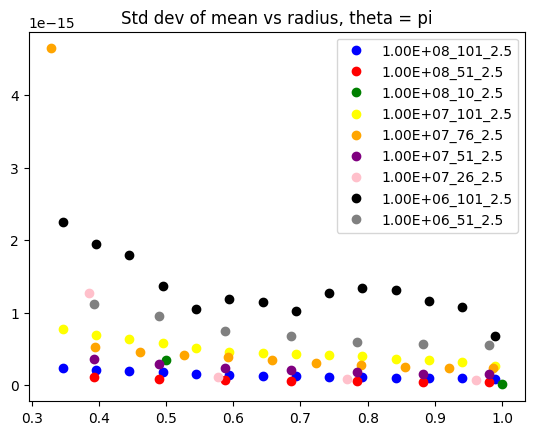

In [6]:
# Plot std dev of mean vs radius at constant angle (theta) for range = (0.3, 1.0)
fig1, ax1 = plt.subplots()

line_handles = []
line_format = "o" # set to "o" for scatter plot, "" for line plot
for k in range(len(plot_storage_1)):	
	line, = ax1.plot(plot_storage_1[k][0], plot_storage_1[k][3], line_format, color=plot_colors[k], label=plot_legend[k])
	line_handles.append(line)

ax1.legend(handles=line_handles)
ax1.set_title("Std dev of mean vs radius, theta = pi")

Text(0.5, 1.0, 'Std dev of mean vs radius, theta = pi')

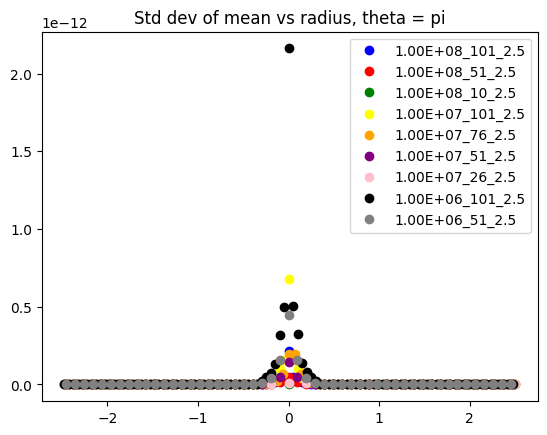

In [7]:
# Plot std dev of mean vs radius at constant angle for entire range
fig3, ax3 = plt.subplots()

line_handles = []
line_format = "o" # set to "o" for scatter plot, "" for line plot
for k in range(len(plot_storage_2)):	
    line, = ax3.plot(plot_storage_2[k][0], plot_storage_2[k][3], line_format, color=plot_colors[k], label=plot_legend[k])
    line_handles.append(line)

ax3.legend(handles=line_handles)
ax3.set_title("Std dev of mean vs radius, theta = pi")

### Step 2: plot std dev as a function of angle

In [8]:
# Note that we reset variables in this block
# Extract parameters to plot = independent variable (radius), dependent variable (energy), standard deviation
plot_storage_3 = []
plot_range_3 = (0, pi)
for j in range(num_files):
    """
    To plot std dev as function of radius:
        - eng_to_plot = energy_storage[j][0]
        - ind_var = 0
        - Adjust plot_rng as desired (entire range --> plt_rng = (0,0))
    
    To plot std dev as function of theta:
        - eng_to_plot = energy_storage[j][1]
        - ind_var = 1
        - Adjust plot_rng as desired
    
    To save figures of energy vs radius/theta, set save=True
    Don't forget to adjust the plot title when changing the independent variable!
    """
    eng_to_plot = energy_storage[j][1]
    plot_tuple_3 = plotter_1D(eng_to_plot, ind_var=1, plot_rng=plot_range_3, std_dev=True, num_Hx=num_Hx[j])
    
    plot_storage_3.append(plot_tuple_3)

Text(0.5, 1.0, 'Std dev of mean vs angle, radius = 0.3 cm')

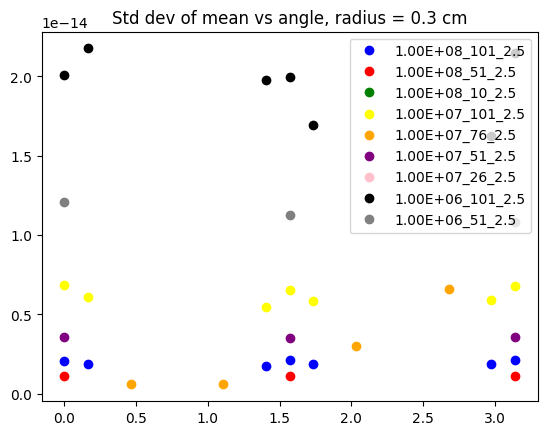

In [9]:
# Plot std dev of mean as function of angle at constant radius
fig2, ax2 = plt.subplots()

line_handles = []
line_format = "o" # set to "o" for scatter plot, "" for line plot
for k in range(len(plot_storage_3)):	
	line, = ax2.plot(plot_storage_3[k][0], plot_storage_3[k][3], line_format, color=plot_colors[k], label=plot_legend[k])
	line_handles.append(line)

ax2.legend(handles=line_handles)
ax2.set_title("Std dev of mean vs angle, radius = 0.3 cm")

### Step 3: std dev vs radius for 1e8/101 bins and 1e7/51 bins

In [52]:
plot_storage_4 = []
#plot_range_4 = (0.5, 2.5)
plot_range_4 = (-2.5, -0.5)
indices = [0, 1, 3, 4, 5, 6]

plot_legend = []
for j in indices:
    # Same as other blocks above
    eng_to_plot = energy_storage[j][0]
    
    # Plot restricted range defined in plot_range_4
    plot_tuple_4 = plotter_1D(eng_to_plot, ind_var=0, plot_rng=plot_range_4, std_dev=True, num_Hx=num_Hx[j])
    
    plot_storage_4.append(plot_tuple_4)
    plot_legend.append(f"{'%.2E' % Decimal(num_Hx[j])}_{num_bins[j]}_{dose_grid_half[j]}")

Text(0.5, 1.0, 'Std dev of mean vs radius, angle = pi')

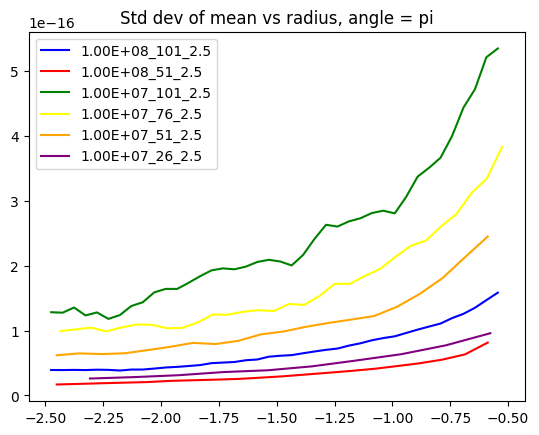

In [55]:
fig4, ax4 = plt.subplots()

line_handles = []
line_format = "" # set to "o" for scatter plot, "" for line plot
for k in range(len(plot_storage_4)):	
	line, = ax4.plot(plot_storage_4[k][0], plot_storage_4[k][3], line_format, color=plot_colors[k], label=plot_legend[k])
	line_handles.append(line)

ax4.legend(handles=line_handles)
ax4.set_title("Std dev of mean vs radius, angle = pi")

Text(0.5, 1.0, 'Energy vs radius, angle = pi')

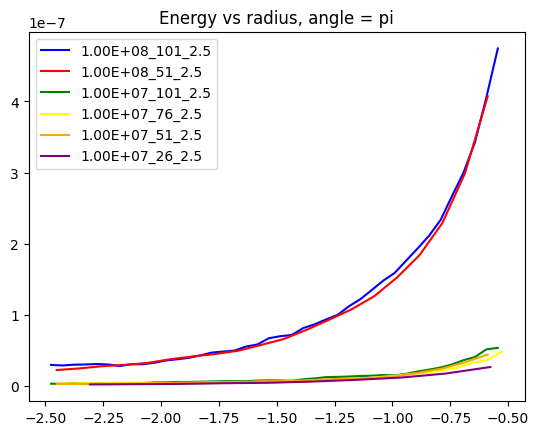

In [56]:
# Plotting energy vs radius for the above runs
fig5, ax5 = plt.subplots()

line_handles = []
line_format = "" # set to "o" for scatter plot, "" for line plot
for k in range(len(plot_storage_4)):	
	line, = ax5.plot(plot_storage_4[k][0], plot_storage_4[k][1], line_format, color=plot_colors[k], label=plot_legend[k])
	line_handles.append(line)

ax5.legend(handles=line_handles)
ax5.set_title("Energy vs radius, angle = pi")